In [1]:
%matplotlib inline
import sys
import os
sys.path.append(os.path.abspath(".."))
import importlib

from functions import color_palettes
importlib.reload(color_palettes)
from functions.color_palettes import *

from functions import utils
importlib.reload(utils)
from functions.utils import *

from functions import config
importlib.reload(config)
from functions.config import *

c:\Users\aoezek\AppData\Local\miniconda3\envs\circadian\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
image_paths = glob.glob("/Users/aylinozek/Desktop/Thesis/thesis_photos_filtered_valid_participants/**/*.jpg", recursive=True)

post_meal_start_min = 0    
post_meal_end_min = 120 

In [ ]:
cgm_complete, participant_ids, metadata = load_and_filter_complete_cgm(
    cgm_path=cgm_path,
    metadata_path=metadata_path,
    days_to_keep=days,
)
cgm_df = analysis_ready_cgm(cgm_complete)
meal_data = pd.read_excel(merged_meal_meta_valid_path)
meal_events_df = extract_meal_events(image_paths)
meal_events_df = clean_meal_events(meal_events_df)

In [ ]:
normalized_meal_segments = extract_normalized_meal_segments(
    meal_events_df,
    cgm_df,
    post_meal_start_min,
    post_meal_end_min
)

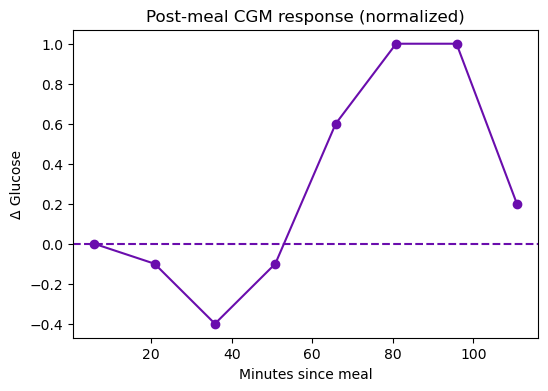

In [ ]:
example = normalized_meal_segments[190]

plt.figure(figsize=(6,4))
plt.plot(example["time_since_meal_min"], example["glucose_norm"], marker="o")
plt.axhline(0, linestyle="--")
plt.xlabel("Minutes since meal")
plt.ylabel("Δ Glucose")
plt.title("Post-meal CGM response (normalized)")
#plt.savefig('C:\Users\aoezek\Desktop\master_thesis\master_thesis\visualisations\meal_response_example.png')
plt.show()

---
##### Recording Rate Analysis: How many meals do we expect from CGM data ?

- Checks the CGM data in sliding windows of 120 min then compare them to the post-meal response pattern templates calculated from the actual recorded meals and their corresponding windows on participant level
- Similar patterns will suggest candidate meal events
---

In [ ]:
df_analysis_ready=extract_normalized_meal_segments_merged(
    meal_data,
    cgm_df,
    post_meal_start_min,
    post_meal_end_min
)
df_analysis_ready.to_excel('C:\Users\aoezek\Desktop\master_thesis\master_thesis\finalised_clean_notebooks\excels\analysis_ready_data.xlsx')
#df_analysis_ready = pd.read_excel(r'C:\Users\aoezek\Desktop\master_thesis\master_thesis\finalised_clean_notebooks\excels\analysis_ready_data2602.xlsx')

In [ ]:
glycemic_valued_meals_df = df_analysis_ready[df_analysis_ready["glycemic_index"] > 0]
len(glycemic_valued_meals_df['meal_id'].unique())

In [ ]:
#-----------------------------------------------------------------------------
#Participant response templates (means) and the distance (similarity) of these templates to the meals
#the 75th percentile of the similarity distance between the meals and the template is the threshold to flag the 
#meal-like windows
#-----------------------------------------------------------------------------

templates=build_participant_template(glycemic_valued_meals_df)
meal_distances = compute_meal_distances(glycemic_valued_meals_df, templates)
# print("Mean:", np.mean(meal_distances))
# print("Median:", np.median(meal_distances))
# print("75th percentile:", np.percentile(meal_distances, 75))
threshold = np.percentile(meal_distances, 75)

In [ ]:
window_df=create_sliding_windows(cgm_df, window_size=8, step_size=1)
#-----------------------------------------------------------------------------
#Dawn phenomenon filtering 
#(there might be slight morning glucose increases (dawn phenomenon) which could possible flagged as candidate meals )
#-----------------------------------------------------------------------------
window_df = window_df[~window_df["datetime"].dt.hour.between(3, 6)]

In [ ]:
candidate_meals = detect_candidate_meals(window_df, templates, threshold)
candidate_meals["end_time"] = (
    candidate_meals["start_time"] + pd.Timedelta(minutes=110)
)
final_meal_candidates_df = collapse_overlapping_meals(candidate_meals)
final_meal_candidates_df=remove_true_meals(final_meal_candidates_df, glycemic_valued_meals_df)
meal_recording_rates=compute_recording_rate(final_meal_candidates_df, glycemic_valued_meals_df)
meal_recording_rates=meal_recording_rates.sort_values(['recording_rate'],ascending=False)
meal_recording_rates

In [ ]:
mean_meal_recording_rate=round(meal_recording_rates["recording_rate"].mean(),3)
mean_meal_recording_rate

In [ ]:
metadata = form_age_groups(
    metadata,
    age_col='age',
    new_col='age_group',
    bins=bins_binary,
    labels=labels_binary
)
metadata = metadata.rename(columns={'ID': 'Participant_id'})
age_included=meal_recording_rates.merge(metadata, on='Participant_id', how='left')

In [ ]:
meal_recording_rates['Participant_id'] = meal_recording_rates['Participant_id'].str.replace('AL', 'P', regex=False)
age_included['Participant_id'] = age_included['Participant_id'].str.replace('AL', 'P', regex=False)
mean_meal_recording_rate = round(meal_recording_rates["recording_rate"].mean(), 3)
# age_included[['Participant_id','recorded_meals','detected_unrecorded','recording_rate','sex','age']].to_latex(
#     "recording_rates_1905_2.tex",
#     index=False,
#     float_format="%.3f"
# )

age_included = age_included.sort_values("recording_rate", ascending=False)

In [ ]:
plt.figure(figsize=(15,6))
sns.barplot(
    data=age_included,
    x="Participant_id",
    y="recording_rate",
    hue="age_group",
    palette=[mixed_palette[1], mixed_palette[2]],
    alpha=0.7,
    dodge=False
)
plt.ylim(0,1)
plt.ylabel("Recording Rate")
plt.xlabel("Participant")
plt.xticks(rotation=55)
plt.title("Meal Recording Rate by Participant")
plt.axhline(mean_meal_recording_rate, linestyle='--',label=f"Mean rate = {mean_meal_recording_rate}")
plt.axhline(0.5, color='red', linestyle='--',label="Recording rate = 0.5")
plt.legend()
plt.tight_layout()
#plt.savefig('C:\\Users\\aoezek\\Desktop\\Thesis\\Thesis_Analysis\\visualisations\\may_visuals\\recording_rate_descending_order_age_1905.png', dpi=400)
plt.show()